# Pokročilé techniky práce s daty a datovými soubory — Python

Čištění, transformace, agregace a spojování tabulek. Navazuje na základní znalost pandas.


## Cíle
- sjednotit soubory s rozdílnými názvy sloupců;
- rozpoznat chybějící hodnoty a duplicity podle významu záznamu;
- provést textové, typové a jednotkové transformace;
- změnit široký a dlouhý formát;
- rozlišit agregaci od skupinové transformace;
- kontrolovat kardinalitu spojení a nespárované záznamy;
- zachovat původ dat a ověřit výsledek před exportem.



In [ ]:
import numpy as np
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

DATA = Path("data")
VYSTUP = Path("vystup")
VYSTUP.mkdir(exist_ok=True)
pd.set_option("display.max_columns", 20)


## 1. Načtení a první kontrola
CSV není jednotný formát v praxi: liší se oddělovače, kódování, zápis čísel i chybějících hodnot. Identifikátory načítáme jako text, aby se například neztratily úvodní nuly.

Leden a únor mají odlišné názvy sloupců. Nejprve zkontrolujeme strukturu, potom je zřetězíme. `concat` přidává řádky; `merge` propojuje záznamy podle klíče.


In [ ]:
leden = pd.read_csv(DATA / "mereni_leden.csv", sep=";", dtype="string")
unor = pd.read_csv(DATA / "mereni_unor.csv", sep=";", dtype="string")
display(leden.head(), unor.head())
leden.info()


,stanice_id,datum,teplota,jednotka,stav,vlhkost,aktualizovano
0,S01,2026-01-01 08:00,"5,6",C,OK,72,2026-01-01 18:00
1,S01,2026-01-01 16:00,<NA>,C,OK,61,2026-01-01 18:00
2,S02,2026-01-01 08:00,"6,9",C,OK,50,2026-01-01 18:00
3,S02,2026-01-01 16:00,"2,4",C,OK,<NA>,2026-01-01 18:00
4,S03,2026-01-01 08:00,"5,3",C,OK,75,2026-01-01 18:00


,station,timestamp,temperature,unit,status,humidity,updated
0,S01,2026-02-01 08:00,"46,8",F,OK,44,2026-02-01 18:00
1,S01,2026-02-01 16:00,"8,6",C,OK,67,2026-02-01 18:00
2,S99,2026-02-01 08:00,"6,3",C,OK,57,2026-02-01 18:00
3,S02,2026-02-01 16:00,"8,7",C,OK,61,2026-02-01 18:00
4,S03,2026-02-01 08:00,"6,6",C,ok,89,2026-02-01 18:00


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 44 entries, 0 to 43
Data columns (total 7 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   stanice_id     44 non-null     string
 1   datum          44 non-null     string
 2   teplota        43 non-null     string
 3   jednotka       44 non-null     string
 4   stav           44 non-null     string
 5   vlhkost        43 non-null     string
 6   aktualizovano  44 non-null     string
dtypes: string(7)
memory usage: 2.5 KB


In [ ]:
# Bez sjednocení názvů vzniknou oddělené sloupce pro stejnou proměnnou.
spatne = pd.concat([leden, unor], ignore_index=True)
display(spatne.isna().sum().to_frame("chybejici"))

prejmenovani = {
    "station": "stanice_id", "timestamp": "datum", "temperature": "teplota",
    "unit": "jednotka", "status": "stav", "humidity": "vlhkost", "updated": "aktualizovano"
}
unor = unor.rename(columns=prejmenovani)
raw = pd.concat([
    leden.assign(zdroj="mereni_leden.csv"),
    unor.assign(zdroj="mereni_unor.csv")
], ignore_index=True)
df = raw.copy()
print("Počet vstupních řádků:", len(df))


,chybejici
stanice_id,42
datum,42
teplota,43
jednotka,42
stav,42
vlhkost,43
aktualizovano,42
station,45
timestamp,44
temperature,44


Počet vstupních řádků: 86


**Úkol:** Co se stane, když jednomu souboru chybí sloupec `vlhkost`? Rozlišujte nepovinný sloupec od povinného. Navrhněte kontrolu, která přeruší zpracování při chybějícím povinném sloupci.

## 2. Nekonzistentní texty a kategorie
Sjednotíme mezery, velikost písmen a ekvivalentní označení. Mapování používáme pro známé ekvivalence. Neznámá kategorie se nemá nenápadně stát platnou hodnotou.


## 2a. Kontrola překlepů a přibližné párování řetězců
Normalizace odstraní rozdíly v zápisu, ale neopraví záměnu, chybějící znak nebo prohození znaků. Přibližné párování (*fuzzy matching*) hledá podobné kandidáty. Zde používáme **referenční číselník**, nikoli nejčastější zápis ve špinavých datech.

**Levenshteinova vzdálenost** je minimální počet vložení, odstranění a záměn znaků. Je to počet operací, ne procento. Prohození sousedních znaků obvykle vyžaduje dvě operace; Damerau–Levenshteinova vzdálenost zahrnuje i transpozici.

Pro výuku definujeme vlastní skóre `100 × (1 − vzdálenost / maximální délka)`. Skóre **není pravděpodobnost správné opravy** a nemusí odpovídat skóre jiné knihovny. Například RapidFuzz `fuzz.ratio` používá normalizovanou Indel podobnost.

Ukázka nepotřebuje další balíček. Pro větší tabulky jsou vhodné optimalizované knihovny, například RapidFuzz.


Pro normalizaci textu lze použít **NFKD** -> **Normalization Form Compatibility Decomposition**

In [ ]:
import unicodedata

def normalizuj_nazev(text):
    # Normalizace pro porovnání; původní názvy pro zobrazení zachováme.
    text = unicodedata.normalize("NFKD",str(text).strip().casefold())
    print(text)
    text = "".join(znak for znak in text if not unicodedata.combining(znak))
    return " ".join(text.split())



In [ ]:
import unicodedata

def normalizuj_nazev(text):
    # Normalizace pro porovnání; původní názvy pro zobrazení zachováme.
    text = unicodedata.normalize("NFKD", str(text).strip().casefold())
    text = "".join(znak for znak in text if not unicodedata.combining(znak))
    return " ".join(text.split())

def levenshtein(a, b):
    predchozi = list(range(len(b) + 1))
    for i, znak_a in enumerate(a, start=1):
        aktualni = [i]
        for j, znak_b in enumerate(b, start=1):
            aktualni.append(min(aktualni[-1] + 1, predchozi[j] + 1,
                                 predchozi[j-1] + (znak_a != znak_b)))
        predchozi = aktualni
    return predchozi[-1]

def podobnost(a, b):
    delka = max(len(a), len(b))
    return 100.0 if delka == 0 else 100 * (1 - levenshtein(a, b) / delka)

reference_nazvu = pd.read_csv(DATA / "stanice_reference_nazvu.csv", dtype="string")
nazvy = pd.read_csv(DATA / "nazvy_stanic_preklepy.csv", dtype="string")
ref_normalizovane = reference_nazvu["nazev"].map(normalizuj_nazev)

def navrh_opravy(text):
    poradi = sorted([(podobnost(normalizuj_nazev(text), normalizuj_nazev(r.nazev)),
                       r.stanice_id, r.nazev) for r in reference_nazvu.itertuples()],
                     key=lambda x: x[0], reverse=True)
    prvni, druhy = poradi[:2]
    return {"navrh_id": prvni[1], "navrh_nazvu": prvni[2], "skore": prvni[0],
            "druhy_kandidat": druhy[2], "druhe_skore": druhy[0],
            "odstup": prvni[0] - druhy[0]}

navrhy = pd.concat([nazvy, nazvy["nazev_zdroj"].apply(navrh_opravy).apply(pd.Series)], axis=1)
# Pouze demonstrativní prahy; nelze je obecně přenést na jiný dataset.
navrhy["silny_navrh"] = (navrhy["skore"] >= 85) & (navrhy["odstup"] >= 15)
display(navrhy.round(1))


NameError: name 'pd' is not defined

Alternativně lze použít hotové knihovny:

In [ ]:
#nekonzistence textových záznamů
%pip install fuzzywuzzy
import fuzzywuzzy
from fuzzywuzzy import process

cities = ['attock', 'bajaur agency', 'bannu', 'bhakkar', 'buner', 'chakwal',
       'chaman', 'charsadda', 'd. i khan', 'd.g khan', 'd.i khan',
       'dara adam khel', 'fateh jang', 'ghallanai, mohmand agency',
       'gujrat', 'hangu', 'haripur', 'hayatabad', 'islamabad',
       'jacobabad', 'karachi', 'karak', 'khanewal', 'khuzdar',
       'khyber agency', 'kohat', 'kuram agency', 'kurram agency',
       'lahore', 'lakki marwat', 'lasbela', 'lower dir', 'malakand',
       'mansehra', 'mardan', 'mohmand agency',
       'mosal kor, mohmand agency', 'multan', 'muzaffarabad',
       'north waziristan', 'nowshehra', 'orakzai agency', 'peshawar',
       'pishin', 'poonch', 'quetta', 'rawalpindi', 'sargodha',
       'sehwan town', 'shabqadar-charsadda', 'shangla', 'shikarpur',
       'sialkot', 'south waziristan', 'sudhanoti', 'sukkur', 'swabi',
       'swat', 'taftan', 'tangi, charsadda district', 'tank', 'taunsa',
       'tirah valley', 'totalai', 'upper dir', 'wagah', 'zhob']

matches = fuzzywuzzy.process.extract("d.i khan", cities, limit=10,
                                     scorer=fuzzywuzzy.fuzz.token_sort_ratio)

matches

[('d. i khan', 100),
 ('d.i khan', 100),
 ('d.g khan', 88),
 ('khanewal', 50),
 ('sudhanoti', 47),
 ('hangu', 46),
 ('kohat', 46),
 ('dara adam khel', 45),
 ('chaman', 43),
 ('mardan', 43)]

### Od kandidáta k opravě: lidské rozhodnutí a audit
I když je nejvyšší skóre relativně vysoké, první a druhý kandidát mohou být téměř stejně dobří. Název `Usti` navíc neobsahuje informaci, která ze dvou stanic je míněna. Nejbližší kandidát se najde i pro stanici, která v číselníku vůbec není.

V této ukázce potvrzujeme jen předem známé opravy. Potvrzení představuje samostatný krok po kontrole zdroje. Produkční audit by měl navíc uvádět osobu, čas, verzi pravidel a zdroj důkazu. Původní sloupec nepřepisujeme.


In [ ]:
schvalene_opravy = {
    "Ústi centrum": "S01", "Decin centrum": "S02", "Teplice centurm": "S03",
    "Usti sever": "S04", " Ústí centrum ": "S01"
}
navrhy["schvalene_id"] = navrhy["nazev_zdroj"].map(schvalene_opravy)
navrhy["rozhodnuti"] = navrhy["schvalene_id"].notna().map({True: "potvrzeno", False: "k provereni"})
navrhy.to_csv(VYSTUP / "audit_oprav_nazvu.csv", index=False)
display(navrhy[["nazev_zdroj", "navrh_nazvu", "skore", "odstup", "rozhodnuti", "schvalene_id"]])

# Volitelně: pip install rapidfuzz. Skóre této knihovny nejsou naše skóre výše.
try:
    from rapidfuzz import process, fuzz
    display(process.extract("teplice centurm", ref_normalizovane.tolist(),
                            scorer=fuzz.ratio, limit=3))
except ImportError:
    print("Volitelná ukázka RapidFuzz přeskočena; hlavní ukázka je bez této závislosti.")


,nazev_zdroj,navrh_nazvu,skore,odstup,rozhodnuti,schvalene_id
0,Ústi centrum,Ústí centrum,100.000000,30.769231,potvrzeno,S01
1,Decin centrum,Děčín centrum,100.000000,30.769231,potvrzeno,S02
2,Teplice centurm,Teplice centrum,86.666667,33.333333,potvrzeno,S03
3,Usti sever,Ústí sever,100.000000,41.666667,potvrzeno,S04
4,Usti,Ústí sever,40.000000,6.666667,k provereni,NaN
5,Brno centrum,Ústí centrum,66.666667,5.128205,k provereni,NaN
6,Ústí centrum,Ústí centrum,100.000000,30.769231,potvrzeno,S01


Volitelná ukázka RapidFuzz přeskočena; hlavní ukázka je bez této závislosti.


**Úkoly pro zkušenější studenty:**
1. Porovnejte stejné prahy pro krátké a dlouhé názvy. Proč jedna chyba ovlivňuje jejich skóre jinak?
2. Přidejte do číselníku téměř shodný název a sledujte odstup prvních dvou kandidátů.
3. Rozdělte záznamy na přesnou shodu po normalizaci, kandidáty k ruční kontrole a záznamy bez dostatečné shody.
4. Na sadě ručně ověřených dvojic vyhodnoťte falešná spojení a nenalezené shody při různých prazích. Prahy nevybírejte na stejných dvojicích, na kterých vykazujete konečnou kvalitu.
5. U velkého číselníku navrhněte *blocking*: kandidáty vybírejte například podle regionu. Vysvětlete, jak chybný region může správného kandidáta předem vyloučit.

Odstranění diakritiky nebo interpunkce může sloučit různé názvy. Při porovnání seřazených slov (`token_sort_ratio`) se zase ztrácí informace o jejich pořadí. Při skutečném spojování vždy zvažte i jiné atributy než text.


In [ ]:
df["stanice_id"] = df["stanice_id"].str.strip().str.upper()
df["jednotka"] = df["jednotka"].str.strip().str.upper()
df["stav_puvodni"] = df["stav"]
stav_normalizovany = df["stav"].str.strip().str.lower()
mapa_stavu = {"ok": "ok", "v provozu": "ok", "porucha": "porucha", "údržba": "udrzba"}
df["stav"] = stav_normalizovany.map(mapa_stavu)
neznama_kategorie = stav_normalizovany.notna() & df["stav"].isna()
display(df.loc[neznama_kategorie, ["stav_puvodni", "zdroj"]])
display(df["stav"].value_counts(dropna=False))


,stav_puvodni,zdroj


,count
stav,
ok,84
porucha,1
udrzba,1


### Regulární výrazy


Regulární výrazy (**regular expressions**, zkráceně **regex**) jsou výkonný nástroj pro vyhledávání a manipulaci s textem. Umožňují popsat vzory v řetězcích a efektivně s nimi pracovat, například při validaci vstupů, extrakci dat nebo nahrazování textu.

V Pythonu se regulární výrazy implementují pomocí modulu `re`.

 - `re.search()` – hledá první výskyt vzoru v textu
 - `re.findall()` – vrátí všechny výskyty vzoru v textu
 - `re.sub()` – nahrazuje veškerý text odpovídající vzoru jiným textem

 **Speciální znaky regulárních výrazů**
 - `^` - kotva začátku textu (text musí začínat konkrétními znaky, aby splnil vzor)
 - `$` - kotva konce text (text musí končit konkrétními znaky aby splnil vzor)
 - `[]` - povolená množina znaků
 - `[a-z]` - malá písmena v rozsahu a-z bez diakritiky
 - `\w` - libovolný znak z rozsahu `[a-zA-Z]` a mezera
 - `[0-9]` - libovolné číslo v rozsahu 0-9
 - `\d` - totéž jako `[0-9]`
 - `*` - počet opakování znaku 0-neomezeně
 - `+` - alespoň jeden výskyt
 - `?` -znak se vyskytuje právě jednou a nebo se vůbec nevyskytuje
 - `{cislo}` - počet opakování znaku
 - `{od,do}` - povolený rozsah opakování znaků
 - `|` - logické "nebo"/or vzoru odpovídají znaky na levé nebo pravé straně operátoru
 - `()` - skupiny znaků, které je nutné vyhodnotit najednou (např: `[fz]|(st)`)
 - `.` -značí libovolný symbol

 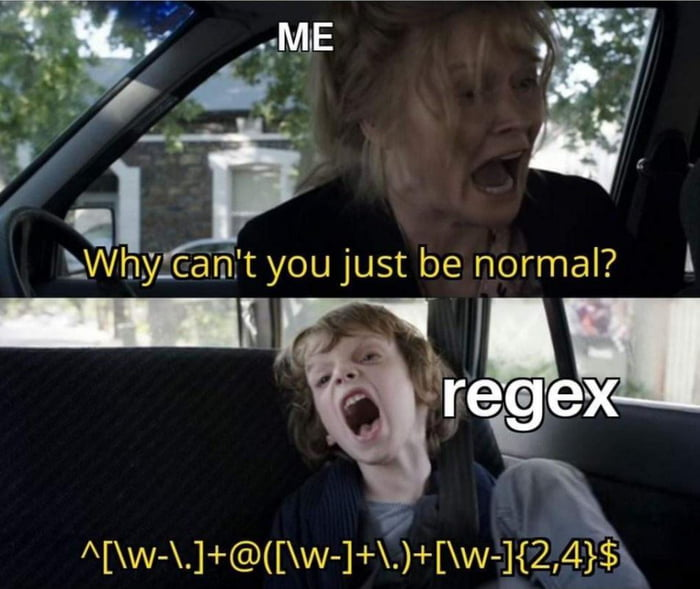

In [ ]:
import re

text = input("zadej studentské číslo")

if re.search(r"^[fz]\d{5}$",text):
  print("OK")
else:
  print("KO")

zadej studentské číslogf26001fbevfizavhveFLZHWB
KO


In [ ]:
import re

# Pavel Frantisek Novak
# Pavel F. Novak

text = input("zadej jméno")

if re.search(r"^[A-Z][a-z]+ (([A-Z][a-z]+ )|([A-Z]\. ))?[A-Z][a-z]+$",text):
  print("OK")
else:
  print("KO")

zadej jménoPavel F. Novak
OK


### Regulární výrazy: validace versus extrakce
`str.fullmatch()` kontroluje celý text, `str.contains()` hledá výskyt a `str.extract()` získává části textu. Vzor `S[0-9]{2}` popisuje písmeno S a dvě číslice. `\w` znamená slovní znaky (včetně číslic a podtržítka), nikoli mezeru.

Syntakticky správný identifikátor ještě nemusí existovat v číselníku — například `S99`.


In [ ]:
format_id_ok = df["stanice_id"].str.fullmatch(r"S[0-9]{2}", na=False)
display(df.loc[~format_id_ok, ["stanice_id", "datum", "zdroj"]])

priklad = pd.Series(["teplota: 12,5 C", "teplota: -3,0 C"], dtype="string")
display(priklad.str.extract(r"teplota:\s*(?P<hodnota>-?[0-9]+,[0-9]+)\s*(?P<jednotka>C)"))


,stanice_id,datum,zdroj
52,<NA>,2026-02-02 08:00,mereni_unor.csv


,hodnota,jednotka
0,"12,5",C
1,"-3,0",C


**Úkol:** Upravte vzor pro identifikátory, aby povoloval dvě nebo tři číslice. Proč by bylo riskantní automaticky opravit `S99` na nejpodobnější existující ID? Podobnost řetězců je návrh ke kontrole, ne důkaz totožnosti.

## 3. Převody typů a jednotek
Použijeme explicitní formát data. Nečitelnou hodnotu převod s `errors="coerce"` označí jako chybějící; současně ji zaznamenáme do přehledu chyb. **To není imputace:** žádnou hodnotu nedoplňujeme.


In [ ]:
chyby_prevodu = []
for sloupec in ["teplota", "vlhkost"]:
    puvodni = df[sloupec].copy()
    df[sloupec] = pd.to_numeric(puvodni.str.replace(",", ".", regex=False), errors="coerce")
    chyba = puvodni.notna() & df[sloupec].isna()
    chyby_prevodu.append(df.loc[chyba, ["stanice_id", "zdroj"]].assign(
        sloupec=sloupec, puvodni_hodnota=puvodni.loc[chyba]))
for sloupec in ["datum", "aktualizovano"]:
    puvodni = df[sloupec].copy()
    df[sloupec] = pd.to_datetime(puvodni, format="%Y-%m-%d %H:%M", errors="coerce")
    chyba = puvodni.notna() & df[sloupec].isna()
    chyby_prevodu.append(df.loc[chyba, ["stanice_id", "zdroj"]].assign(
        sloupec=sloupec, puvodni_hodnota=puvodni.loc[chyba]))
chyby_prevodu = pd.concat(chyby_prevodu, ignore_index=True)
display(chyby_prevodu)

# Fahrenheit -> Celsius. Původní hodnota a jednotka zůstávají dohledatelné v raw.
df["teplota_C"] = df["teplota"].where(df["jednotka"].eq("C"))
je_f = df["jednotka"].eq("F")
df.loc[je_f, "teplota_C"] = (df.loc[je_f, "teplota"] - 32) * 5 / 9
display(df.loc[je_f, ["teplota", "jednotka", "teplota_C"]])


,stanice_id,zdroj,sloupec,puvodni_hodnota
0,S02,mereni_leden.csv,teplota,chyba
1,S03,mereni_unor.csv,vlhkost,nezjištěno
2,S03,mereni_leden.csv,datum,neznámé


,teplota,jednotka,teplota_C
44,46.8,F,8.222222


## 4. Chybějící hodnoty a mazání řádků
V pandas může chybění představovat `NaN`, `pd.NA` nebo `NaT`; kontrolujeme je pomocí `isna()`. Prázdný řetězec či zvláštní kód se musí podle dokumentace zdroje rozpoznat zvlášť.

Pro naši analýzu jsou povinné ID, čas a teplota v °C. Chybějící vlhkost není důvodem vyřadit použitelné měření teploty. Mazání může změnit zastoupení skupin; vždy uvádíme, kolik dat bylo vyřazeno.


In [ ]:
profil_na = pd.DataFrame({"pocet": df.isna().sum(), "podil": df.isna().mean()})
display(profil_na)
povinne = ["stanice_id", "datum", "teplota_C"]
vyrazeno_na = df.loc[df[povinne].isna().any(axis=1)].copy()
pred = len(df)
df = df.dropna(subset=povinne).copy()
print("Vyřazeno kvůli povinným údajům:", pred - len(df))
print("Počet po smazání podle celé tabulky:", len(df.dropna()))
print("Počet po smazání jen podle povinných sloupců:", len(df))
# Další možnosti: dropna(how="all"), dropna(axis=1), dropna(thresh=...).


,pocet,podil
stanice_id,1,0.011628
datum,1,0.011628
teplota,2,0.023256
jednotka,0,0.000000
stav,0,0.000000
vlhkost,2,0.023256
aktualizovano,0,0.000000
zdroj,0,0.000000
stav_puvodni,0,0.000000
teplota_C,2,0.023256


Vyřazeno kvůli povinným údajům: 4
Počet po smazání podle celé tabulky: 80
Počet po smazání jen podle povinných sloupců: 82


## 5. Duplicity: totožné řádky a verze stejného měření
Shodné hodnoty nejsou automaticky chybná duplicita. Rozhodující je význam záznamu.

1. Odstraníme úplně totožné řádky.
2. Vyhledáme opakovaný klíč stanice–čas.
3. Podle pravidla tohoto syntetického zdroje ponecháme nejnovější opravu, určenou časem `aktualizovano`. Při shodném čase aktualizace by konfliktní hodnoty vyžadovaly další kontrolu.

`drop_duplicates()` bez přiřazení původní tabulku nezmění. Parametr `keep=False` odstraní všechny výskyty duplicitní skupiny, nikoli jen nadbytečné kopie.


In [ ]:
uplne_duplicity = df.loc[df.duplicated(keep=False)].copy()
pred = len(df)
df = df.drop_duplicates().copy()
print("Odstraněné úplné kopie:", pred - len(df))
klic = ["stanice_id", "datum"]
display(df.loc[df.duplicated(subset=klic, keep=False),
               klic + ["teplota_C", "aktualizovano"]].sort_values(klic))
pred = len(df)
serazeno = df.sort_values("aktualizovano", kind="stable")
stare_verze = serazeno.loc[serazeno.duplicated(subset=klic, keep="last")].copy()
df = serazeno.drop_duplicates(subset=klic, keep="last").copy()
print("Odstraněné starší verze:", pred - len(df))


Odstraněné úplné kopie: 1


,stanice_id,datum,teplota_C,aktualizovano
2,S02,2026-01-01 08:00:00,6.9,2026-01-01 18:00:00
43,S02,2026-01-01 08:00:00,7.5,2026-01-08 10:00:00


Odstraněné starší verze: 1


**Úkol:** Porovnejte výběr `keep="first"` před seřazením a po seřazení. Jak se změní výsledek pro opravené měření? Proč není `drop_duplicates(subset=["stanice_id"])` správné?

## 6. Spojování tabulek a kontrola klíčů
Měření → číselník je vztah **N:1**: stanice má více měření, ale v číselníku jeden řádek.

- `left`: všechna měření; nespárovaná mají chybějící metadata.
- `inner`: jen spárovaná měření.
- `outer`: všechny klíče z obou stran.

`validate="many_to_one"` ověřuje očekávanou kardinalitu. `indicator=True` ukazuje původ řádku. Pozor: pandas při spojování může párovat i chybějící klíče; naše povinné klíče jsme odstranili před spojením.


In [ ]:
stanice = pd.read_csv(DATA / "stanice.csv", dtype="string")
chybny = pd.read_csv(DATA / "stanice_chybny_ciselnik.csv", dtype="string")
bez_kontroly = df.merge(chybny, on="stanice_id", how="left")
print("Řádky před spojením / s chybným číselníkem:", len(df), len(bez_kontroly))
print("Součet teplot před / po:", df["teplota_C"].sum(), bez_kontroly["teplota_C"].sum())
# Součet zde slouží jen jako kontrolní veličina, ne jako meteorologická statistika.
try:
    df.merge(chybny, on="stanice_id", how="left", validate="many_to_one")
except pd.errors.MergeError as chyba:
    print("Očekávaná chyba kontroly:", chyba)

spojeno = df.merge(stanice, on="stanice_id", how="left",
                  validate="many_to_one", indicator=True)
nesparovane = spojeno.loc[spojeno["_merge"].eq("left_only")].copy()
display(nesparovane[klic + ["teplota_C", "zdroj"]])
# Cílem další analýzy je přehled známých stanic. Neznámá ID ponecháme v reportu.
mereni = spojeno.loc[spojeno["_merge"].eq("both")].drop(columns="_merge").copy()


Řádky před spojením / s chybným číselníkem: 80 106
Součet teplot před / po: 482.3222222222222 642.3444444444445
Očekávaná chyba kontroly: Merge keys are not unique in right dataset; not a many-to-one merge


,stanice_id,datum,teplota_C,zdroj
41,S99,2026-02-01 08:00:00,6.3,mereni_unor.csv


**Úkol:** Zkuste `inner` a `outer` a porovnejte počty řádků. Jak najdete stanice bez jediného měření? Co nastane, když se jeden klíč opakuje na obou stranách? Pro m výskytů vlevo a n vpravo vznikne pro daný klíč m × n řádků.

## 7. Transformace a agregace
Odvodíme kalendářní údaje. Měření se stavem `porucha` či `udrzba` ponecháme v čištěném exportu, ale v přehledu provozních měření je nepoužijeme. Jde o známý stav zdroje, nikoli detekci odlehlých hodnot.

`size` počítá řádky; `count` jen neprázdné hodnoty daného sloupce. Průměr vždy doprovázíme počtem měření.


In [ ]:
mereni["den"] = mereni["datum"].dt.normalize()
mereni["mesic"] = mereni["datum"].dt.to_period("M").astype("string")
provozni = mereni.loc[mereni["stav"].eq("ok")].copy()
prehled = provozni.groupby(["stanice_id", "nazev", "mesic"], as_index=False).agg(
    pocet_mereni=("teplota_C", "size"),
    prumer_teploty=("teplota_C", "mean"),
    minimum=("teplota_C", "min"), maximum=("teplota_C", "max"),
    pocet_vlhkosti=("vlhkost", "count"), prumer_vlhkosti=("vlhkost", "mean")
)
display(prehled)
assert prehled["pocet_mereni"].sum() == len(provozni)


,stanice_id,nazev,mesic,pocet_mereni,prumer_teploty,minimum,maximum,pocet_vlhkosti,prumer_vlhkosti
0,S01,Ústí centrum,2026-01,11,4.981818,3.3,6.8,11,63.545455
1,S01,Ústí centrum,2026-02,13,7.340171,5.2,9.6,13,55.769231
2,S02,Děčín centrum,2026-01,14,5.892857,2.4,9.3,13,65.153846
3,S02,Děčín centrum,2026-02,12,6.083333,4.1,8.7,12,64.416667
4,S03,Teplice centrum,2026-01,13,4.692308,1.6,7.3,13,63.846154
5,S03,Teplice centrum,2026-02,14,7.107143,4.4,9.7,13,64.538462


### Agregace versus skupinová transformace
Agregace vytvoří jeden řádek za skupinu. `transform()` vrátí výsledek zarovnaný s původními řádky — například průměr stanice ke každému měření. Odchylka je zde nová proměnná, ne pravidlo pro hledání nebo mazání extrémů.


In [ ]:
provozni["prumer_stanice"] = provozni.groupby("stanice_id")["teplota_C"].transform("mean")
provozni["odchylka_od_prumeru"] = provozni["teplota_C"] - provozni["prumer_stanice"]
provozni["poradi_v_case"] = provozni.sort_values("datum").groupby("stanice_id").cumcount() + 1
provozni["podil_mereni_stanice"] = 1 / provozni.groupby("stanice_id")["teplota_C"].transform("size")
display(provozni[["stanice_id", "datum", "teplota_C", "prumer_stanice", "odchylka_od_prumeru"]].head())


,stanice_id,datum,teplota_C,prumer_stanice,odchylka_od_prumeru
0,S01,2026-01-01 08:00:00,5.6,6.259259,-0.659259
1,S02,2026-01-01 16:00:00,2.4,5.980769,-3.580769
2,S03,2026-01-01 08:00:00,5.3,5.944444,-0.644444
3,S03,2026-01-01 16:00:00,5.0,5.944444,-0.944444
4,S01,2026-01-02 08:00:00,3.3,6.259259,-2.959259


**Úkol:** Vypočtěte denní průměr pro každou stanici a připojte jej ke každému měření pomocí `transform()`. Potom vypočtěte měsíční průměr dvěma způsoby: přímo ze všech měření a jako průměr denních průměrů. Proč se mohou lišit, pokud mají dny různý počet měření?

## 8. Široký a dlouhý formát
Široká tabulka má měsíce ve sloupcích. Dlouhá tabulka ukládá měsíc jako hodnotu jedné proměnné; snadněji se seskupuje a vizualizuje. Samostatný soubor s počty je pouze ilustrace formátu, nikoli kontrolní výsledek našich měření.


In [ ]:
siroka = pd.read_csv(DATA / "pocty_mereni_siroka.csv", dtype={"stanice_id": "string"})
dlouha = siroka.melt(id_vars="stanice_id", var_name="mesic", value_name="pocet")
zpet = dlouha.pivot(index="stanice_id", columns="mesic", values="pocet")
display(siroka, dlouha, zpet)

# pivot vyžaduje jednu hodnotu na kombinaci index–sloupec.
konflikt = pd.concat([dlouha, dlouha.iloc[[0]]], ignore_index=True)
try:
    konflikt.pivot(index="stanice_id", columns="mesic", values="pocet")
except ValueError as chyba:
    print("Očekávaná chyba pivotu:", chyba)
# pivot_table umí agregovat. Použijeme jej jen pokud agregace dává věcný smysl.
display(konflikt.pivot_table(index="stanice_id", columns="mesic", values="pocet", aggfunc="sum"))


,stanice_id,leden,unor
0,S01,40,42
1,S02,38,41
2,S03,39,40


,stanice_id,mesic,pocet
0,S01,leden,40
1,S02,leden,38
2,S03,leden,39
3,S01,unor,42
4,S02,unor,41
5,S03,unor,40


mesic,leden,unor
stanice_id,,
S01,40,42
S02,38,41
S03,39,40


Očekávaná chyba pivotu: Index contains duplicate entries, cannot reshape


mesic,leden,unor
stanice_id,,
S01,80,42
S02,38,41
S03,39,40


**Úkol:** Proč by součet v předchozí ukázce byl chybný, pokud přidaný řádek představuje náhodně zkopírovaný záznam? Vytvořte širokou tabulku skutečných měsíčních průměrů ze souhrnu `prehled`.

## 9. Kontroly, audit a export
Původní data neměníme. Reporty zachovávají vyřazené řádky a důvody rozhodnutí. CSV neuchovává schéma datových typů; po opětovném načtení je potřeba obnovit typy. Pro opakované analytické zpracování může být vhodný Parquet, který vyžaduje například `pyarrow`.


,krok,pocet
0,vstup,86
1,chybejici_povinne,4
2,uplne_kopie,1
3,stare_verze,1
4,nezname_stanice,1
5,zname_stanice,79
6,provozni_mereni,77


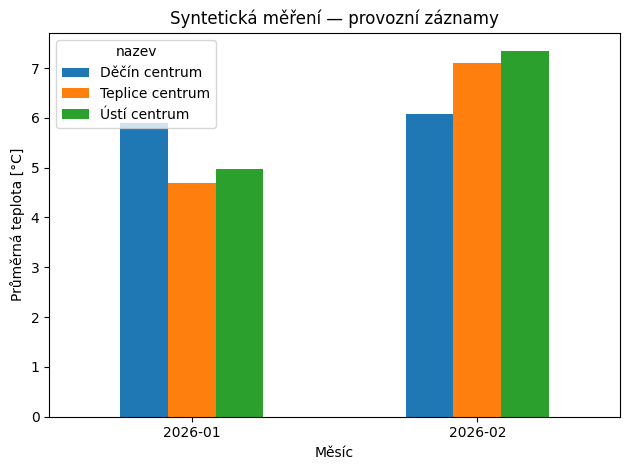

In [ ]:
audit = pd.DataFrame({
    "krok": ["vstup", "chybejici_povinne", "uplne_kopie", "stare_verze", "nezname_stanice", "zname_stanice", "provozni_mereni"],
    "pocet": [len(raw), len(vyrazeno_na), len(uplne_duplicity) - len(uplne_duplicity.drop_duplicates()),
              len(stare_verze), len(nesparovane), len(mereni), len(provozni)]
})
display(audit)
for nazev, tabulka in {
    "mereni_cista": mereni, "prehled_mesicni": prehled,
    "chyby_prevodu": chyby_prevodu, "vyrazene_chybejici": vyrazeno_na,
    "stare_verze": stare_verze, "nesparovane": nesparovane, "audit": audit
}.items():
    tabulka.to_csv(VYSTUP / f"{nazev}.csv", index=False, encoding="utf-8")

ax = prehled.pivot(index="mesic", columns="nazev", values="prumer_teploty").plot.bar()
ax.set_ylabel("Průměrná teplota [°C]")
ax.set_xlabel("Měsíc")
ax.set_title("Syntetická měření — provozní záznamy")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


## 10. Samostatné procvičení
1. Sestavte funkci pro načtení a sjednocení jednoho měsíčního souboru. Parametrem bude cesta a slovník pro přejmenování sloupců.
2. Načtěte měsíční soubory pomocí `Path.glob("mereni_*.csv")`; zachovejte název zdroje. Nepoužívejte jeden slovník slepě pro neznámá schémata.
3. Pro každou stanici a měsíc vypočtěte podíl záznamů se stavem `ok` ze všech záznamů známých stanic po čištění.
4. Vytvořte denní souhrn s počtem měření teploty a počtem známých hodnot vlhkosti.
5. Vyhledejte měření bez protějšku v číselníku a exportujte jejich jedinečná ID.
6. Přidejte do číselníku stanici bez měření a najděte ji pomocí spojování tabulek.
7. Popište, které řádky a proč byly vyřazeny. Jak by se výsledek změnil při `dropna()` přes všechny sloupce?


## 11. Kvalita labelů a targetu

Čisté příznaky nezaručují správný target. Pro klasifikaci může být nesprávný **label**; u regrese chybná cílová hodnota. Příčiny zahrnují překlep, chybu exportu, záměnu objektů, rozdílné instrukce nebo skutečně nejednoznačný případ.

Použijeme **samostatná syntetická data**: 121 záznamů o 120 objektech, čtyři číselné příznaky a anotace tří osob. Nejde o biologicky validovaný dataset. Jeden objekt je zaznamenán dvakrát; některé labely jsou záměrně změněné. Soubor `reference_labelu_pro_vyucujiciho.csv` uchovává původní třídu generátoru pouze pro následné vyhodnocení cvičení — **nikdy není vstupním příznakem modelu ani podkladem pro jeho trénink**.

Postupujeme od levných kontrol k náročnějším:
1. Povolené třídy, chybění, referenční integrita.
2. Konfliktní labely stejného objektu a neshody anotátorů.
3. Doménová pravidla a shoda anotátorů.
4. Modelová diagnostika a ruční přezkoumání.


In [ ]:
objekty = pd.read_csv(DATA / "objekty_priznaky.csv")
anotace = pd.read_csv(DATA / "anotace.csv", dtype="string")
tridy = ["druh_A", "druh_B"]

chyba_labelu = anotace["label"].isna() | ~anotace["label"].isin(tridy)
display(anotace.loc[chyba_labelu])
platne_anotace = anotace.loc[~chyba_labelu].copy()

# Neshody u jednoho záznamu. nunique nepočítá chybějící hodnoty.
pocty_labelu = platne_anotace.groupby("zaznam_id")["label"].nunique()
konfliktni_id = pocty_labelu.loc[pocty_labelu > 1].index
display(platne_anotace.loc[platne_anotace["zaznam_id"].isin(konfliktni_id)].head(15))

# Konflikty stejného objektu napříč opakovanými záznamy u jednoho anotátora.
anotace_objektu = platne_anotace.merge(objekty[["zaznam_id", "objekt_id"]],
                                     on="zaznam_id", validate="many_to_one")
konflikty_objektu = anotace_objektu.groupby(["objekt_id", "anotator"])["label"].nunique()
display(konflikty_objektu.loc[konflikty_objektu > 1])


,zaznam_id,anotator,label
22,Z007,B,druh_C
26,Z008,C,<NA>


,zaznam_id,anotator,label
6,Z002,A,druh_B
7,Z002,B,druh_A
8,Z002,C,druh_A
36,Z012,A,druh_A
37,Z012,B,druh_A
38,Z012,C,druh_B
54,Z018,A,druh_B
55,Z018,B,druh_A
56,Z018,C,druh_B
66,Z022,A,druh_B


,,label
objekt_id,anotator,
O004,A,2


### Věcná pravidla versus statistické podezření
Věk −5 nebo datum události před narozením je logický či doménový rozpor. Nízká pravděpodobnost labelu podle modelu je pouze podezření. Pravidla vždy závisí na definici proměnných: věk 0 může být platný, záporná teplota také.

U anotací může být i nesouhlas věcně oprávněný. Překryv tříd v 2D projekci (např. UMAP) sám o sobě nedokazuje chybné labely: projekce ztrácí informaci a třídy se mohou přirozeně překrývat.


In [ ]:
kontrola = pd.DataFrame({"id": [1,2,3,4], "vek": [17,21,0,-5],
                         "target": ["dospely","dospely","dospely","dite"]})
# V tomto cvičení definujeme dospělost jako věk >= 18.
kontrola["neplatny_vek"] = kontrola["vek"] < 0
kontrola["rozpor_targetu"] = ((kontrola["target"].eq("dospely") & (kontrola["vek"] < 18))
                             | (kontrola["target"].eq("dite") & (kontrola["vek"] >= 18)))
display(kontrola)


### Shoda anotátorů: prostá shoda a Cohenovo kappa
Pro dvojici osob nejprve počítáme podíl shod. Cohenovo kappa upravuje shodu o očekávanou náhodnou shodu odvozenou z četností jejich labelů:

$$\kappa = \frac{p_o-p_e}{1-p_e},$$

kde $p_o$: skutečně pozorovaný podíl shod,\
$p_e$: očekávaná shoda při nezávislém přiřazování se stejnými četnostmi kategorií.

Kappa není přesnost a žádný anotátor zde není referenční pravda. Výsledek závisí i na zastoupení tříd; při dominanci jedné třídy může být prostá shoda vysoká a kappa nízká. Univerzální hranice „dobré shody“ nejsou vhodné bez kontextu. Chybějící či nepovolené anotace nepočítáme jako další třídu; uvádíme počet společně hodnocených případů.


In [ ]:
from sklearn.metrics import cohen_kappa_score
from itertools import combinations

anotace_siroka = platne_anotace.pivot(index="zaznam_id", columns="anotator", values="label")
shody = []
for a, b in combinations(anotace_siroka.columns, 2):
    dvojice = anotace_siroka[[a,b]].dropna()
    shody.append({"anotator_1": a, "anotator_2": b, "pocet": len(dvojice),
                  "prosta_shoda": (dvojice[a] == dvojice[b]).mean(),
                  "kappa": cohen_kappa_score(dvojice[a], dvojice[b], labels=tridy)})
display(pd.DataFrame(shody))
display(pd.crosstab(anotace_siroka["A"], anotace_siroka["B"]))


**Úkol:** Vytvořte dvě umělé anotace se 95 % třídy A, porovnejte prostou shodu a kappa. Potom zjistěte, které dvojice tříd si jednotliví anotátoři zaměňují. Může se většina anotátorů shodnout na nesprávném labelu? Ano — například při společném nepochopení instrukcí.

### Modelová diagnostika pomocí out-of-fold predikcí
Model naučený na stejném řádku může jeho label zapamatovat. Proto pro každý záznam získáme predikci z modelu, jehož trénovací data **neobsahují tento objekt**. Opakované záznamy téhož objektu držíme ve stejné skupině (*group*), takže neuniknou mezi tréninkem a testem.

Pro ilustraci diagnostikujeme anotace osoby A. Neprohlašujeme je za pravdu. V každém ze tří opakování pětidílné crossvalidace použijeme dva různé modely. Každý řádek má tedy **šest out-of-fold predikcí, nikoli patnáct predikcí z foldů**. Standardizace se učí pouze na trénovací části uvnitř pipeline. Číselné příznaky tohoto datasetu nemají chybějící hodnoty.

Sledujeme:
- medián `p(y_obs)`: pravděpodobnost původně pozorovaného labelu;
- podíl predikcí s `p(y_obs) < 0.2`;
- četnost nesouhlasu predikovaného a pozorovaného labelu;
- medián normalizované entropie: nejistotu modelu.

Nízká entropie a nízké `p(y_obs)` znamenají sebejistý nesouhlas; vysoká entropie spíše nejednoznačný případ. Ani jedno samo o sobě nedokazuje chybu anotace. Skóre `1 − median_p_obs` není pravděpodobnost chyby labelu a nekalibrované modelové pravděpodobnosti mají omezenou interpretaci.


In [ ]:
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.base import clone

labely_A = platne_anotace.loc[platne_anotace["anotator"].eq("A"), ["zaznam_id", "label"]]
model_data = objekty.merge(labely_A, on="zaznam_id", validate="one_to_one").reset_index(drop=True)
priznaky = ["delka", "sirka", "hmotnost", "signal"]
X = model_data[priznaky]
y = model_data["label"].map({"druh_A": 0, "druh_B": 1}).to_numpy(dtype=int)
groups = model_data["objekt_id"].to_numpy()
assert X.notna().all().all()
modely = {
    "logisticka_regrese": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "nahodny_les": RandomForestClassifier(n_estimators=100, min_samples_leaf=3, random_state=42)
}
vsechny_proba = []
for seed in [10,20,30]:
    cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=seed)
    rozdeleni = list(cv.split(X, y, groups))
    for nazev, zaklad in modely.items():
        proba = np.full((len(X), 2), np.nan)
        pocet_predikci = np.zeros(len(X), dtype=int)
        for train, test in rozdeleni:
            assert not set(groups[train]) & set(groups[test])
            model = clone(zaklad).fit(X.iloc[train], y[train])
            assert np.array_equal(model.classes_, [0,1])
            proba[test] = model.predict_proba(X.iloc[test])
            pocet_predikci[test] += 1
        assert (pocet_predikci == 1).all() and np.isfinite(proba).all()
        vsechny_proba.append(proba)

P = np.stack(vsechny_proba)  # opakování × modely, řádky, třídy
p_obs = np.take_along_axis(P, y[None,:,None], axis=2).squeeze(axis=2)
entropie = -(P * np.log(np.clip(P, 1e-12, 1))).sum(axis=2) / np.log(2)
diagnostika = model_data[["zaznam_id", "objekt_id", "label"]].copy()
diagnostika["median_p_obs"] = np.median(p_obs, axis=0)
diagnostika["frac_below_0_2"] = (p_obs < 0.2).mean(axis=0)
diagnostika["frac_pred_disagree"] = (P.argmax(axis=2) != y[None,:]).mean(axis=0)
diagnostika["median_entropie"] = np.median(entropie, axis=0)
diagnostika["skore_k_provereni"] = 1 - diagnostika["median_p_obs"]
diagnostika["neshoda_anotatoru"] = diagnostika["zaznam_id"].isin(konfliktni_id)
diagnostika = diagnostika.sort_values("skore_k_provereni", ascending=False)
display(diagnostika.head(15).round(3))
diagnostika.to_csv(VYSTUP / "diagnostika_labelu.csv", index=False)


### Od diagnostiky k rozhodnutí
Přezkoumávající osoba dostane původní label, původní data, ostatní anotace a důvod upozornění. Možná rozhodnutí: ponechat, opravit po ověření, vyžádat další anotaci nebo ponechat jako nejednoznačný případ. Model labely automaticky nepřepisuje.

Nesouhlas může způsobit i slabý model, chybějící důležitý příznak, menšinová podskupina nebo změna dat v čase. Více podobných modelů nezaručuje nezávislý důkaz. Při ladění pravidel podle výsledků z testovací sady by vznikl další únik informací; nezávislé závěrečné hodnocení držíme odděleně.


In [ ]:
fronta_k_revizi = diagnostika.head(15).copy()
fronta_k_revizi["rozhodnuti"] = "ceka_na_kontrolu"
fronta_k_revizi["novy_label"] = pd.NA
fronta_k_revizi["duvod_rozhodnuti"] = pd.NA
fronta_k_revizi["kontroloval"] = pd.NA
fronta_k_revizi["cas_kontroly"] = pd.NA
fronta_k_revizi.to_csv(VYSTUP / "fronta_k_revizi.csv", index=False)

# Až nyní otevřeme učitelskou referenci, abychom zhodnotili syntetický experiment.
# V reálném datasetu taková spolehlivá reference obvykle není k dispozici.
reference_labelu = pd.read_csv(DATA / "reference_labelu_pro_vyucujiciho.csv")
vyhodnoceni = diagnostika.merge(reference_labelu, on="zaznam_id", validate="one_to_one")
vyhodnoceni["zmeneny_label_v_simulaci"] = vyhodnoceni["label"] != vyhodnoceni["label_generatoru"]
k = 15
print("Změněných labelů osoby A:", vyhodnoceni["zmeneny_label_v_simulaci"].sum())
print(f"Podíl skutečně změněných labelů mezi prvními {k} kandidáty:",
      vyhodnoceni.head(k)["zmeneny_label_v_simulaci"].mean())
# Toto je precision@k pro tuto syntetickou ukázku, nikoli přesnost klasifikačního modelu.




### Zdroje k rozšíření
- [RapidFuzz: Levenshteinova vzdálenost](https://rapidfuzz.github.io/RapidFuzz/Usage/distance/Levenshtein.html)
- [RapidFuzz: skóre podobnosti](https://rapidfuzz.github.io/RapidFuzz/Usage/fuzz.html)
- [scikit-learn: Cohenovo kappa](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.cohen_kappa_score.html)
- [scikit-learn: StratifiedGroupKFold](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.StratifiedGroupKFold.html)
- [scikit-learn: out-of-fold predikce](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.cross_val_predict.html)
